In [1]:
from IPython.display import display
import requests
import pandas as pd


In [2]:
dataset_slug = "bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2025"
meta_url = f"https://www.data.gouv.fr/api/1/datasets/{dataset_slug}/"
dataset = requests.get(meta_url).json()

# 1. Collect the 2025 CSV resources
resources = {
    res["title"]: res
    for res in dataset["resources"]
    if res["format"] == "csv" and "2025" in res["title"]
}
for title, res in resources.items():
    print(f"{title} -> rid: {res['id']}")


def load_resource(res, **kwargs):
    url = f"https://www.data.gouv.fr/fr/datasets/r/{res['id']}"
    r = requests.get(url, timeout=60)
    r.raise_for_status()

    # Detect separator from the header line
    header = r.content[:2000].decode("utf-8-sig", errors="replace").splitlines()[0]
    sep = ";" if header.count(";") > header.count(",") else ","

    return pd.read_csv(
        io.BytesIO(r.content),
        sep=sep,
        encoding="utf-8-sig",   # also strips a BOM if present
        dtype={"Num_Acc": str, "id_vehicule": str, "num_veh": str},
        low_memory=False,
        **kwargs,
    )

dfs = {title: load_resource(res) for title, res in resources.items()}

for title, df in dfs.items():
    print(f"\n=== {title} ===")
    print(df.shape)
    print(df.head(3))

vehicules-immatricule-baac-2025.csv -> rid: 9827fd15-eebc-461e-a4af-b48594ce3c6b
Vehicules_2025.csv -> rid: 58ba05bf-661d-4c59-b504-3d77336ccb8f
Usagers_2025.csv -> rid: 513b5a4a-20cc-4ee2-a0c8-5e5a82ad69a4
Lieux_2025.csv -> rid: 29db11b7-dad2-480f-943d-725ffdeb9a27
Caract_2025.csv -> rid: e5a1c21d-17cb-4ee0-b85f-8e34aba4d309


NameError: name 'io' is not defined

In [ ]:
print(dfs.keys())

dict_keys(['vehicules-immatricule-baac-2025.csv', 'Vehicules_2025.csv', 'Usagers_2025.csv', 'Lieux_2025.csv', 'Caract_2025.csv'])


# Visualizing all datasets

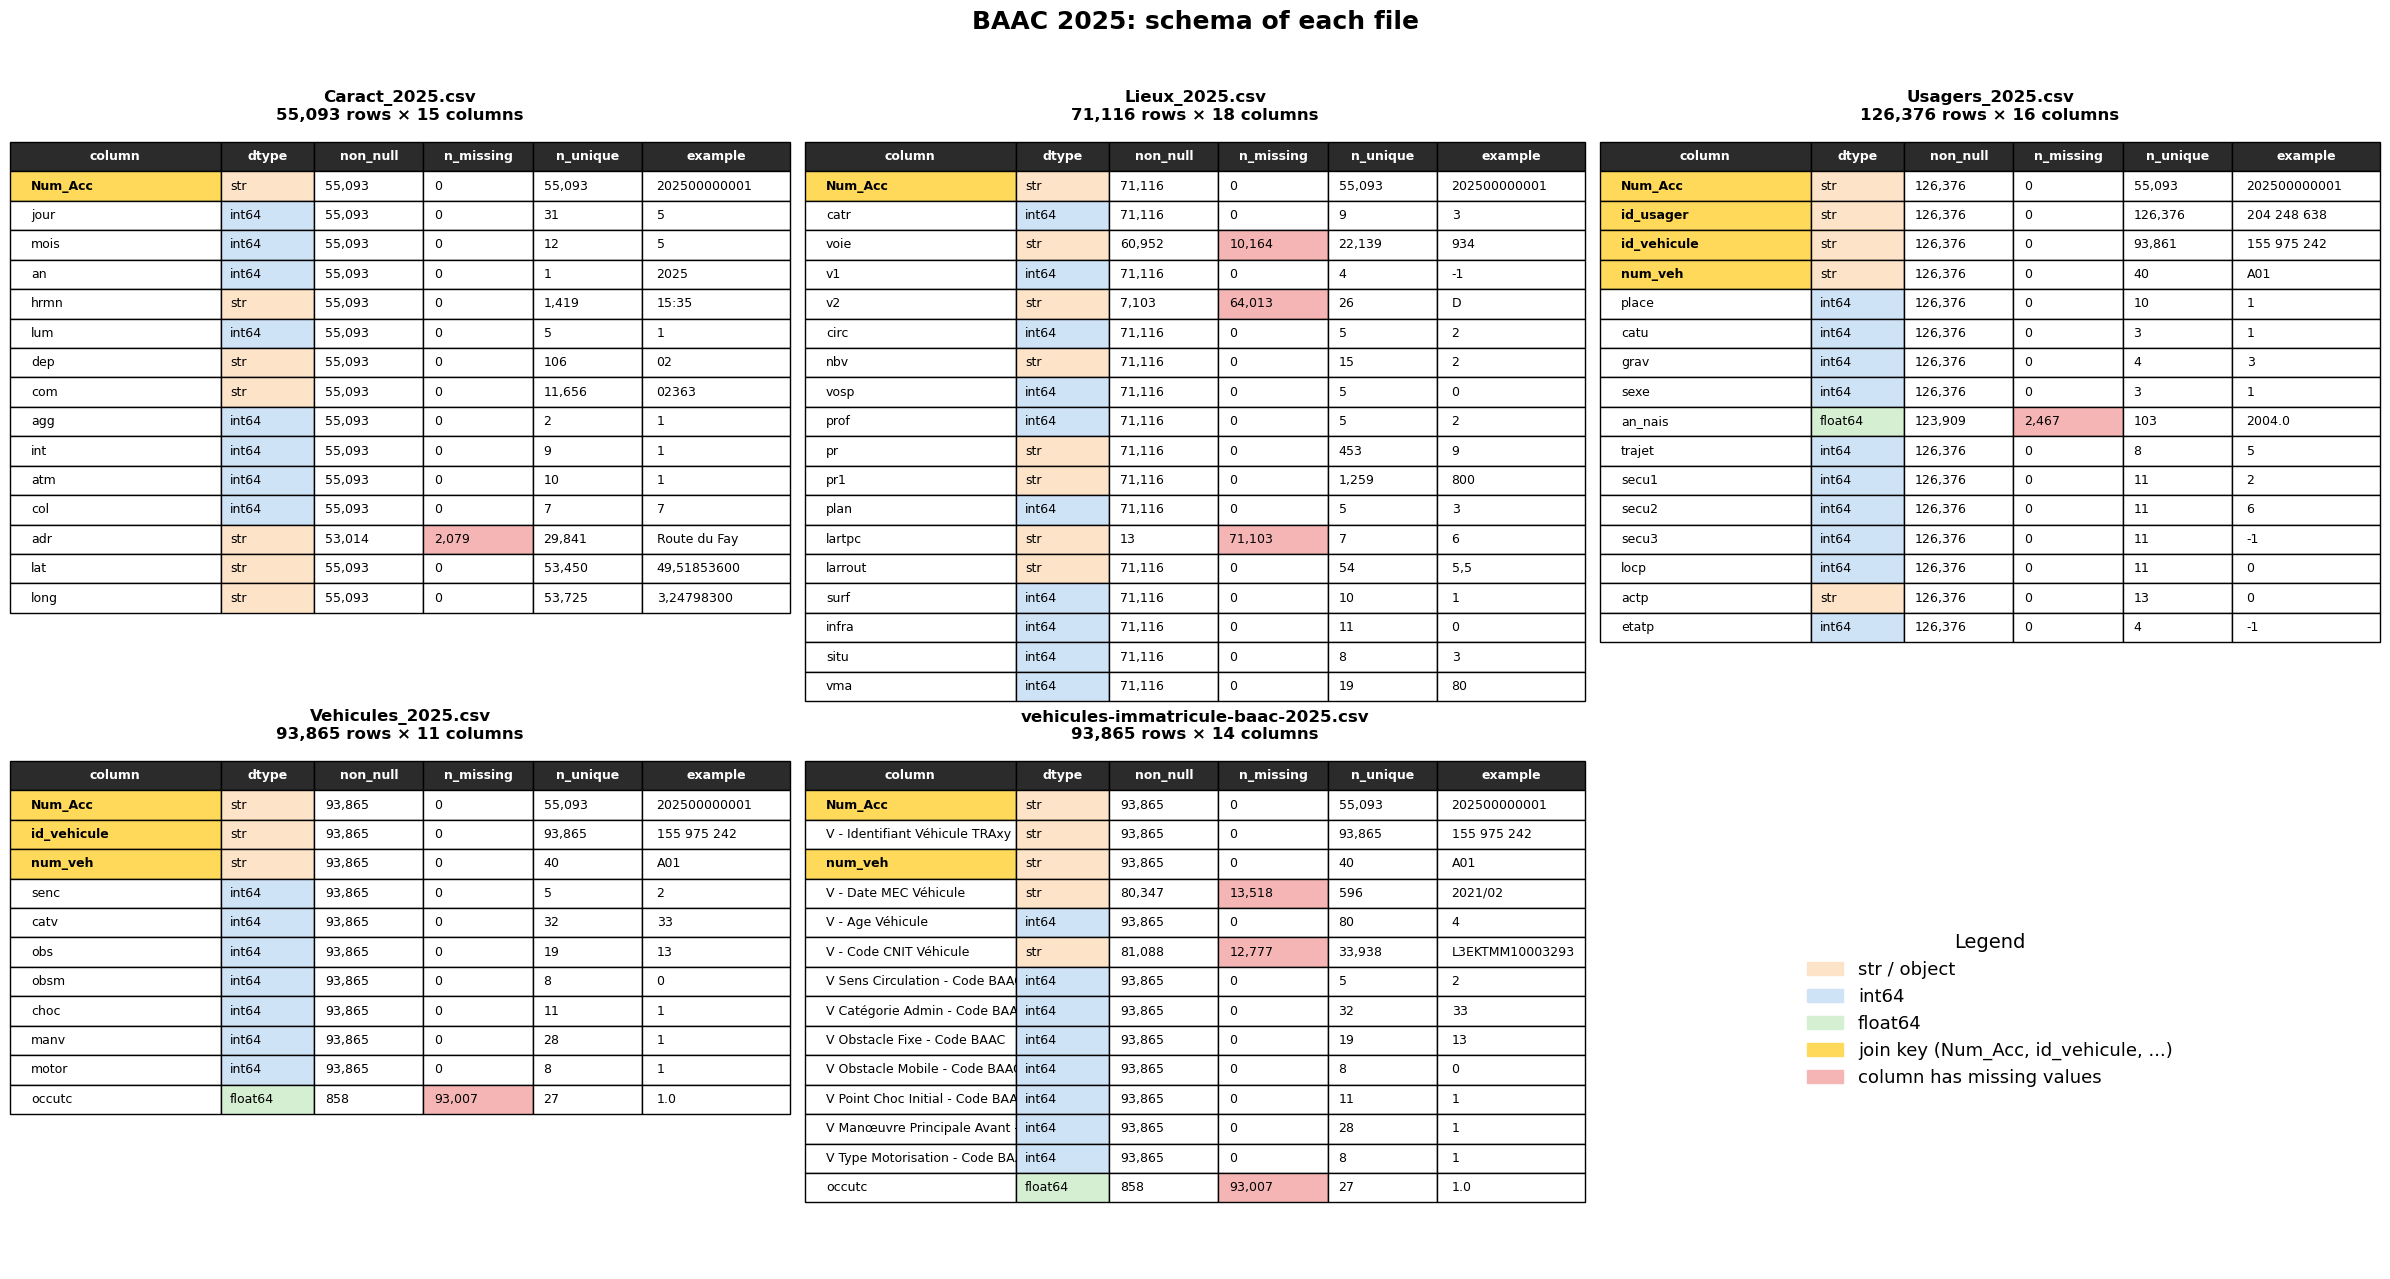

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Fix stray whitespace in column names (Vehicules has 'id_vehicule\n')
for df in dfs.values():
    df.columns = df.columns.str.strip()

def describe_columns(df):
    return pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "non_null": df.notna().sum().values,
        "n_missing": df.isna().sum().values,
        "n_unique": df.nunique().values,
        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None
                    for c in df.columns],
    })

schemas = {t: describe_columns(df) for t, df in dfs.items()}

order = ["Caract_2025.csv", "Lieux_2025.csv", "Usagers_2025.csv",
         "Vehicules_2025.csv", "vehicules-immatricule-baac-2025.csv"]
order = [t for t in order if t in schemas]

DTYPE_COLORS = {"str": "#fde4c8", "object": "#fde4c8", "int64": "#cfe3f7",
                "float64": "#d4efd2"}
KEY_COLOR = "#ffd95a"       # join keys
MISSING_COLOR = "#f5b5b5"   # columns with missing values
JOIN_KEYS = {"Num_Acc", "id_vehicule", "id_usager", "num_veh"}

fig, axes = plt.subplots(2, 3, figsize=(24, 13))
axes = axes.flatten()
headers = ["column", "dtype", "non_null", "n_missing", "n_unique", "example"]

for ax, title in zip(axes, order):
    schema = schemas[title]
    ax.axis("off")
    ax.set_title(f"{title}\n{len(dfs[title]):,} rows × {len(schema)} columns",
                 fontsize=12, fontweight="bold", pad=8)

    cell_text = [[str(r.column), r.dtype, f"{r.non_null:,}", f"{r.n_missing:,}",
                  f"{r.n_unique:,}", str(r.example)[:18]]
                 for r in schema.itertuples()]

    tbl = ax.table(cellText=cell_text, colLabels=headers, loc="upper center",
                   cellLoc="left", colWidths=[0.27, 0.12, 0.14, 0.14, 0.14, 0.19])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.55)

    for j in range(len(headers)):                      # header row
        tbl[0, j].set_facecolor("#2b2b2b")
        tbl[0, j].set_text_props(color="white", fontweight="bold")

    for i, r in enumerate(schema.itertuples(), start=1):
        tbl[i, 1].set_facecolor(DTYPE_COLORS.get(r.dtype, "#eeeeee"))
        if r.column in JOIN_KEYS:
            tbl[i, 0].set_facecolor(KEY_COLOR)
            tbl[i, 0].set_text_props(fontweight="bold")
        if r.n_missing > 0:
            tbl[i, 3].set_facecolor(MISSING_COLOR)

# Use the spare 6th panel for the legend
for ax in axes[len(order):]:
    ax.axis("off")
legend_ax = axes[-1]
handles = [
    mpatches.Patch(color="#fde4c8", label="str / object"),
    mpatches.Patch(color="#cfe3f7", label="int64"),
    mpatches.Patch(color="#d4efd2", label="float64"),
    mpatches.Patch(color=KEY_COLOR, label="join key (Num_Acc, id_vehicule, ...)"),
    mpatches.Patch(color=MISSING_COLOR, label="column has missing values"),
]
legend_ax.legend(handles=handles, loc="center", fontsize=13, title="Legend",
                 title_fontsize=14, frameon=False)

fig.suptitle("BAAC 2025: schema of each file", fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("baac_2025_schemas.png", dpi=200, bbox_inches="tight")
plt.show()

# Filtering based on region: Ile de France (75)

In [ ]:
import pandas as pd
import geopandas as gpd
import requests
from IPython.display import display

# ---- 1. Communes bordering the périphérique (INSEE codes, from memory) ----
PERIPH = {
    # 92 Hauts-de-Seine
    "92051": "Neuilly-sur-Seine", "92044": "Levallois-Perret", "92024": "Clichy",
    "92012": "Boulogne-Billancourt", "92040": "Issy-les-Moulineaux",
    "92075": "Vanves", "92046": "Malakoff", "92049": "Montrouge",
    # 93 Seine-Saint-Denis
    "93070": "Saint-Ouen-sur-Seine", "93066": "Saint-Denis", "93001": "Aubervilliers",
    "93055": "Pantin", "93061": "Le Pré-Saint-Gervais", "93045": "Les Lilas",
    "93006": "Bagnolet", "93048": "Montreuil",
    # 94 Val-de-Marne
    "94080": "Vincennes", "94067": "Saint-Mandé", "94018": "Charenton-le-Pont",
    "94041": "Ivry-sur-Seine", "94043": "Le Kremlin-Bicêtre", "94037": "Gentilly",
}

# ---- 2. Verify against official boundaries: which communes touch Paris? ----
def get_communes(dep):
    url = (f"https://geo.api.gouv.fr/communes?codeDepartement={dep}"
           "&fields=nom,code,contour&format=geojson&geometry=contour")
    return gpd.GeoDataFrame.from_features(requests.get(url, timeout=60).json()["features"],
                                          crs="EPSG:4326")

paris_poly = gpd.GeoDataFrame.from_features(
    requests.get("https://geo.api.gouv.fr/communes/75056?fields=nom,code,contour"
                 "&format=geojson&geometry=contour", timeout=60).json()["features"]
    if "features" in requests.get("https://geo.api.gouv.fr/communes/75056?fields=nom,code,contour"
                 "&format=geojson&geometry=contour", timeout=60).json()
    else [requests.get("https://geo.api.gouv.fr/communes/75056?fields=nom,code,contour"
                 "&format=geojson&geometry=contour", timeout=60).json()],
    crs="EPSG:4326").geometry.iloc[0]

nearby = pd.concat([get_communes(d) for d in ["92", "93", "94"]], ignore_index=True)
touching = nearby[nearby.geometry.buffer(0.0002).intersects(paris_poly)]
api_set = set(touching["code"])

print("Touching Paris per official boundaries:", len(api_set))
print("In my list but NOT touching Paris:", {c: PERIPH[c] for c in PERIPH if c not in api_set})
print("Touching Paris but NOT in my list:",
      touching.loc[~touching["code"].isin(PERIPH), ["code", "nom"]].to_dict("records"))

Touching Paris per official boundaries: 29
In my list but NOT touching Paris: {}
Touching Paris but NOT in my list: [{'code': '92062', 'nom': 'Puteaux'}, {'code': '92064', 'nom': 'Saint-Cloud'}, {'code': '92073', 'nom': 'Suresnes'}, {'code': '94033', 'nom': 'Fontenay-sous-Bois'}, {'code': '94042', 'nom': 'Joinville-le-Pont'}, {'code': '94052', 'nom': 'Nogent-sur-Marne'}, {'code': '94069', 'nom': 'Saint-Maurice'}]


C:\Users\blanc\AppData\Local\Temp\ipykernel_16524\622090348.py:38: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  touching = nearby[nearby.geometry.buffer(0.0002).intersects(paris_poly)]


In [ ]:
# strict périphérique list (my list, minus anything the check says doesn't touch Paris)
COMMUNES = {c for c in PERIPH if c in api_set}


INCLUDE_PARIS = False   # set True to also keep Paris itself

# ---- 3. Filter all five dataframes via Num_Acc ----
caract_all = dfs["Caract_2025.csv"]
caract_all["dep"] = caract_all["dep"].astype(str).str.strip()
caract_all["com"] = caract_all["com"].astype(str).str.strip()

mask = caract_all["com"].isin(COMMUNES)
if INCLUDE_PARIS:
    mask |= caract_all["dep"] == "75"
acc = set(caract_all.loc[mask, "Num_Acc"])

dfs_ring = {t: df[df["Num_Acc"].isin(acc)].copy() for t, df in dfs.items()}
names = {**PERIPH, **dict(zip(nearby["code"], nearby["nom"]))}

caract_r = dfs_ring["Caract_2025.csv"]
caract_r["commune_name"] = caract_r["com"].map(names)

print(f"\nAccidents in scope: {len(acc):,}")
print("Communes with no accident found:", sorted(COMMUNES - set(caract_r["com"])))
display(caract_r["commune_name"].value_counts().to_frame("accidents"))

# Push the commune to the other tables
geo = caract_r[["Num_Acc", "dep", "com", "commune_name"]].drop_duplicates("Num_Acc")
for t in dfs_ring:
    if t != "Caract_2025.csv":
        dfs_ring[t] = dfs_ring[t].merge(geo, on="Num_Acc", how="left")


Accidents in scope: 1,417
Communes with no accident found: []


,accidents
commune_name,
Saint-Denis,256
Boulogne-Billancourt,145
Montreuil,122
Ivry-sur-Seine,96
Neuilly-sur-Seine,90
Clichy,84
Aubervilliers,81
Saint-Ouen-sur-Seine,79
Issy-les-Moulineaux,73


In [ ]:
from baac import BAACDataset
from commune_analysis import build_periphery_dataset, CommuneAggregator

ds = BAACDataset.from_titled_frames(dfs, year=2025)
ring = build_periphery_dataset(ds, include_paris=True)
agg = PeripheryAggregator(ring)
agg.by_commune()

ImportError: cannot import name 'PeripheryAggregator' from 'commune_analysis' (c:\Users\blanc\Python_projects\roadsafety_policy\commune_analysis.py)